# 🧠 Brain Tumor Classification — v2.0
### EfficientNet-B0 | Focal Loss | Fine-Tuning Profond

> **Cible :** Accuracy > 90% | Glioma Recall > 90%

| Amélioration | Détail |
|---|---|
| **FocalLoss** | Pénalise les cas difficiles (γ=2.0) |
| **WeightedRandomSampler** | Boost glioma ×1.5 |
| **Dégel profond** | features.5, 6, 7 + classifier |
| **AdamW + CosineAnnealing** | LR différencié par couche |
| **EarlyStopping** | Patience=7, sauvegarde auto |
| **Gradient Clipping** | max_norm=1.0 |


## 0. Montage Google Drive (Colab)

In [18]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Imports

In [19]:
# ============================================================
# 1. IMPORTS
# ============================================================

import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, WeightedRandomSampler
from torch import nn, optim

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize


## 2. Device

In [20]:
# ============================================================
# 2. DEVICE
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Device: {device}")


✅ Device: cuda


## 3. Dataset Path

In [21]:
# ============================================================
# 3. DATASET PATH
# ============================================================

dataset_path = "/content/drive/MyDrive/archive"

train_dir = os.path.join(dataset_path, "Training")
test_dir  = os.path.join(dataset_path, "Testing")


## 4. Transforms Améliorés
- `ColorJitter` simule les variations de contraste IRM
- `RandomAffine` + `RandomVerticalFlip` renforcent la généralisation


In [22]:
# ============================================================
# 4. TRANSFORMS AMÉLIORÉS
#    — Augmentation plus agressive pour mieux généraliser
#    — ColorJitter simule les variations de contraste IRM
# ============================================================

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(20),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.85, 1.15)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])


## 5. Datasets

In [23]:
# ============================================================
# 5. DATASETS
# ============================================================

train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)
test_dataset  = datasets.ImageFolder(test_dir,  transform=test_transforms)

class_names = train_dataset.classes
num_classes = len(class_names)

print(f"✅ Classes ({num_classes}): {class_names}")
print(f"✅ Train: {len(train_dataset)} images | Test: {len(test_dataset)} images")


✅ Classes (4): ['glioma', 'meningioma', 'notumor', 'pituitary']
✅ Train: 5600 images | Test: 1600 images


## 6. Weighted Random Sampler
> Force le modèle à voir équitablement toutes les classes.  
> Boost ×1.5 sur le gliome — critique car c'est la classe la plus mal détectée.


In [24]:
# ============================================================
# 6. WEIGHTED RANDOM SAMPLER
#    — Force le modèle à voir équitablement toutes les classes
#    — Crucial pour le gliome (sous-représenté dans l'apprentissage)
# ============================================================

targets = torch.tensor(train_dataset.targets)
class_counts = torch.bincount(targets).float()

print(f"\n📊 Distribution des classes (train):")
for i, name in enumerate(class_names):
    print(f"   {name}: {int(class_counts[i])} images")

# Poids inversement proportionnels à la fréquence
GLIOMA_BOOST = 1.5   # Facteur supplémentaire pour le glioma
sample_class_weights = 1.0 / class_counts
sample_class_weights[class_names.index("glioma")] *= GLIOMA_BOOST

sample_weights = sample_class_weights[targets]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)



📊 Distribution des classes (train):
   glioma: 1400 images
   meningioma: 1400 images
   notumor: 1400 images
   pituitary: 1400 images


## 7. DataLoaders

In [25]:
# ============================================================
# 7. DATALOADERS
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    sampler=sampler,          # Remplace shuffle=True
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


## 8. Focal Loss
> **FL(pt) = −αt · (1 − pt)^γ · log(pt)**  
> - Bien meilleur que CrossEntropy pour les données médicales déséquilibrées  
> - `gamma=2.0` : valeur standard recommandée dans la littérature  
> - Poids glioma = **3.0** → une erreur sur un gliome coûte 3× plus cher


In [26]:
# ============================================================
# 8. FOCAL LOSS
#    — Pénalise davantage les exemples mal classifiés
#    — Bien meilleur que CrossEntropy pour les données médicales
#    — gamma=2.0 : valeur standard recommandée dans la littérature
# ============================================================

class FocalLoss(nn.Module):
    """
    Focal Loss pour classification multi-classes déséquilibrée.

    FL(pt) = -alpha_t * (1 - pt)^gamma * log(pt)

    Args:
        gamma  : facteur de focalisation (défaut=2.0)
        weight : poids par classe (tensor)
    """

    def __init__(self, gamma=2.0, weight=None):
        super().__init__()
        self.gamma  = gamma
        self.weight = weight

    def forward(self, inputs, targets):
        ce_loss = nn.functional.cross_entropy(
            inputs, targets,
            weight=self.weight,
            reduction='none'
        )
        pt     = torch.exp(-ce_loss)
        focal  = ((1 - pt) ** self.gamma) * ce_loss
        return focal.mean()


# Poids par classe pour la loss
# [glioma, meningioma, notumor, pituitary]  ← ordre alphabétique
loss_class_weights = torch.tensor([3.0, 1.5, 0.8, 1.0]).to(device)

criterion = FocalLoss(gamma=2.0, weight=loss_class_weights)

print("\n✅ Focal Loss initialisée")
print(f"   Poids: {dict(zip(class_names, loss_class_weights.cpu().tolist()))}")



✅ Focal Loss initialisée
   Poids: {'glioma': 3.0, 'meningioma': 1.5, 'notumor': 0.800000011920929, 'pituitary': 1.0}


## 9. Modèle EfficientNet-B0
> Dégel de `features.5`, `features.6`, `features.7` + `classifier`  
> Nouveau head : **Dropout → Linear(256) → ReLU → Dropout → Linear(4)**


In [27]:
# ============================================================
# 9. MODÈLE EfficientNet-B0
#    — Dégel des couches features.5, 6, 7 + classifier
#    — Meilleure adaptation aux caractéristiques des IRM
# ============================================================

model = models.efficientnet_b0(pretrained=True)

# Geler toutes les couches d'abord
for param in model.parameters():
    param.requires_grad = False

# Dégeler features.5, 6, 7 et le classifier
UNFREEZE_LAYERS = ["features.5", "features.6", "features.7", "classifier"]

for name, param in model.named_parameters():
    if any(layer in name for layer in UNFREEZE_LAYERS):
        param.requires_grad = True

# Remplacer le classifier final
num_features = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=0.4, inplace=True),
    nn.Linear(num_features, 256),
    nn.ReLU(),
    nn.Dropout(p=0.3),
    nn.Linear(256, num_classes)
)

model = model.to(device)

# Afficher les couches entraînables
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"\n✅ Modèle EfficientNet-B0 chargé")
print(f"   Paramètres entraînables : {trainable:,} / {total:,} ({100*trainable/total:.1f}%)")
print(f"   Couches dégelées        : {UNFREEZE_LAYERS}")



✅ Modèle EfficientNet-B0 chargé
   Paramètres entraînables : 3,615,692 / 4,336,512 (83.4%)
   Couches dégelées        : ['features.5', 'features.6', 'features.7', 'classifier']


## 10. Optimiseur + Scheduler
> - **LR différencié** : features → `5e-6`, classifier → `1e-4`  
> - **CosineAnnealingLR** : descente douce sur 30 epochs


In [28]:
# ============================================================
# 10. OPTIMISEUR + SCHEDULER
#     — Différents LR selon la profondeur des couches
#     — CosineAnnealingLR : descente douce sans plateau brutal
# ============================================================

EPOCHS = 30

# Groupes de paramètres avec LR différenciés
param_groups = [
    {
        "params": [p for n, p in model.named_parameters()
                   if "features" in n and p.requires_grad],
        "lr": 5e-6,
        "name": "features"
    },
    {
        "params": [p for n, p in model.named_parameters()
                   if "classifier" in n and p.requires_grad],
        "lr": 1e-4,
        "name": "classifier"
    },
]

optimizer = optim.AdamW(param_groups, weight_decay=1e-4)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=1e-7
)

print(f"\n✅ Optimiseur AdamW | Scheduler CosineAnnealing | {EPOCHS} epochs")



✅ Optimiseur AdamW | Scheduler CosineAnnealing | 30 epochs


## 11. Early Stopping

In [29]:
# ============================================================
# 11. EARLY STOPPING
# ============================================================

class EarlyStopping:
    """
    Arrête l'entraînement si la val loss ne s'améliore pas.
    Sauvegarde automatiquement le meilleur modèle.
    """

    def __init__(self, patience=7, min_delta=0.001, path="best_model.pth"):
        self.patience   = patience
        self.min_delta  = min_delta
        self.path       = path
        self.best_loss  = float("inf")
        self.counter    = 0
        self.stop       = False

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter   = 0
            torch.save(model.state_dict(), self.path)
            print(f"   💾 Meilleur modèle sauvegardé (loss={val_loss:.4f})")
        else:
            self.counter += 1
            print(f"   ⏳ EarlyStopping: {self.counter}/{self.patience}")
            if self.counter >= self.patience:
                self.stop = True

early_stopping = EarlyStopping(
    patience=7,
    path="/content/brain_tumor_best_v2.pth"
)


## 12. Boucle d'Entraînement

In [30]:
# ============================================================
# 12. BOUCLE D'ENTRAÎNEMENT COMPLÈTE
# ============================================================

def train_model(model, epochs=EPOCHS):

    history = {
        "train_loss": [],
        "train_acc":  [],
        "val_loss":   [],
        "val_acc":    []
    }

    print("\n" + "="*60)
    print("  DÉBUT DE L'ENTRAÎNEMENT")
    print("="*60)

    for epoch in range(epochs):

        # ─── Phase TRAIN ────────────────────────────────────
        model.train()
        running_loss = 0.0
        correct = total = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss    = criterion(outputs, labels)
            loss.backward()

            # Gradient clipping — évite les explosions de gradient
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()

            running_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            total   += labels.size(0)
            correct += (preds == labels).sum().item()

        train_loss = running_loss / len(train_loader)
        train_acc  = 100.0 * correct / total

        # ─── Phase VALIDATION ───────────────────────────────
        model.eval()
        val_loss = val_correct = val_total = 0

        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs  = model(images)
                loss     = criterion(outputs, labels)
                val_loss    += loss.item()
                _, preds     = torch.max(outputs, 1)
                val_total   += labels.size(0)
                val_correct += (preds == labels).sum().item()

        val_loss /= len(test_loader)
        val_acc   = 100.0 * val_correct / val_total

        scheduler.step()

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"\nEpoch [{epoch+1:02d}/{epochs}]")
        print(f"  Train → Loss: {train_loss:.4f} | Acc: {train_acc:.2f}%")
        print(f"  Val   → Loss: {val_loss:.4f}   | Acc: {val_acc:.2f}%")
        print(f"  LR features : {scheduler.get_last_lr()[0]:.2e} | "
              f"LR classifier: {scheduler.get_last_lr()[-1]:.2e}")

        early_stopping(val_loss, model)
        if early_stopping.stop:
            print(f"\n🛑 Early stopping à l'epoch {epoch+1}")
            break

    print("\n" + "="*60)
    print("  ENTRAÎNEMENT TERMINÉ")
    print("="*60)

    return history


## 13. Lancement de l'Entraînement

In [31]:
# ============================================================
# 13. LANCEMENT DE L'ENTRAÎNEMENT
# ============================================================

history = train_model(model, epochs=EPOCHS)

# Charger le meilleur modèle sauvegardé
model.load_state_dict(torch.load("/content/brain_tumor_best_v2.pth"))
print("\n✅ Meilleur modèle chargé pour l'évaluation")



  DÉBUT DE L'ENTRAÎNEMENT

Epoch [01/30]
  Train → Loss: 1.0531 | Acc: 46.02%
  Val   → Loss: 0.8914   | Acc: 65.31%
  LR features : 4.99e-06 | LR classifier: 9.97e-05
   💾 Meilleur modèle sauvegardé (loss=0.8914)

Epoch [02/30]
  Train → Loss: 0.5531 | Acc: 74.07%
  Val   → Loss: 0.7554   | Acc: 71.25%
  LR features : 4.95e-06 | LR classifier: 9.89e-05
   💾 Meilleur modèle sauvegardé (loss=0.7554)

Epoch [03/30]
  Train → Loss: 0.4673 | Acc: 78.00%
  Val   → Loss: 0.7026   | Acc: 76.62%
  LR features : 4.88e-06 | LR classifier: 9.76e-05
   💾 Meilleur modèle sauvegardé (loss=0.7026)

Epoch [04/30]
  Train → Loss: 0.4065 | Acc: 81.30%
  Val   → Loss: 0.7185   | Acc: 77.25%
  LR features : 4.79e-06 | LR classifier: 9.57e-05
   ⏳ EarlyStopping: 1/7

Epoch [05/30]
  Train → Loss: 0.3822 | Acc: 82.16%
  Val   → Loss: 0.6897   | Acc: 81.19%
  LR features : 4.67e-06 | LR classifier: 9.33e-05
   💾 Meilleur modèle sauvegardé (loss=0.6897)

Epoch [06/30]
  Train → Loss: 0.3487 | Acc: 83.96%
  V

## 14. Courbes d'Entraînement

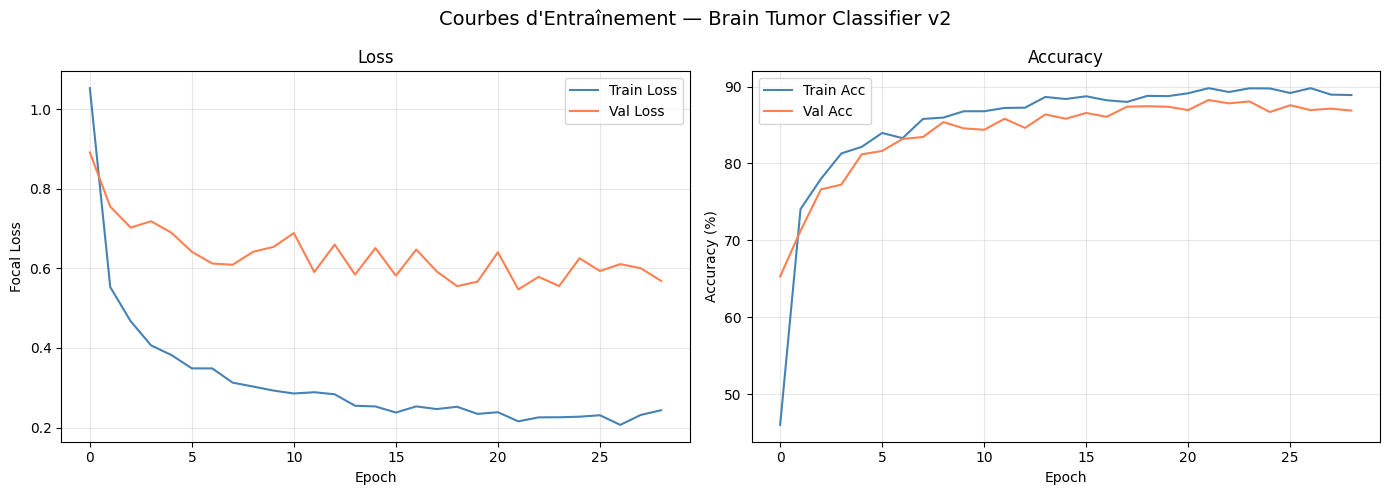

📊 Courbes sauvegardées → /content/training_curves.png


In [32]:
# ============================================================
# 14. COURBES D'ENTRAÎNEMENT
# ============================================================

def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Courbes d'Entraînement — Brain Tumor Classifier v2", fontsize=14)

    axes[0].plot(history["train_loss"], label="Train Loss", color="steelblue")
    axes[0].plot(history["val_loss"],   label="Val Loss",   color="coral")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Focal Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history["train_acc"], label="Train Acc", color="steelblue")
    axes[1].plot(history["val_acc"],   label="Val Acc",   color="coral")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("/content/training_curves.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("📊 Courbes sauvegardées → /content/training_curves.png")

plot_history(history)


## 15. Évaluation Complète
Métriques produites :
- Accuracy & Classification Report
- Matrice de confusion (brute + normalisée)
- Courbes ROC + AUC par classe
- Recall par classe avec alertes visuelles



  TEST ACCURACY : 88.2500%

📋 Classification Report:

              precision    recall  f1-score   support

      glioma       0.93      0.78      0.85       400
  meningioma       0.83      0.84      0.84       400
     notumor       0.83      0.99      0.90       400
   pituitary       0.96      0.92      0.94       400

    accuracy                           0.88      1600
   macro avg       0.89      0.88      0.88      1600
weighted avg       0.89      0.88      0.88      1600


🔢 Confusion Matrix (brute):
 [[311  43  45   1]
 [ 16 337  34  13]
 [  1   4 395   0]
 [  6  22   3 369]]


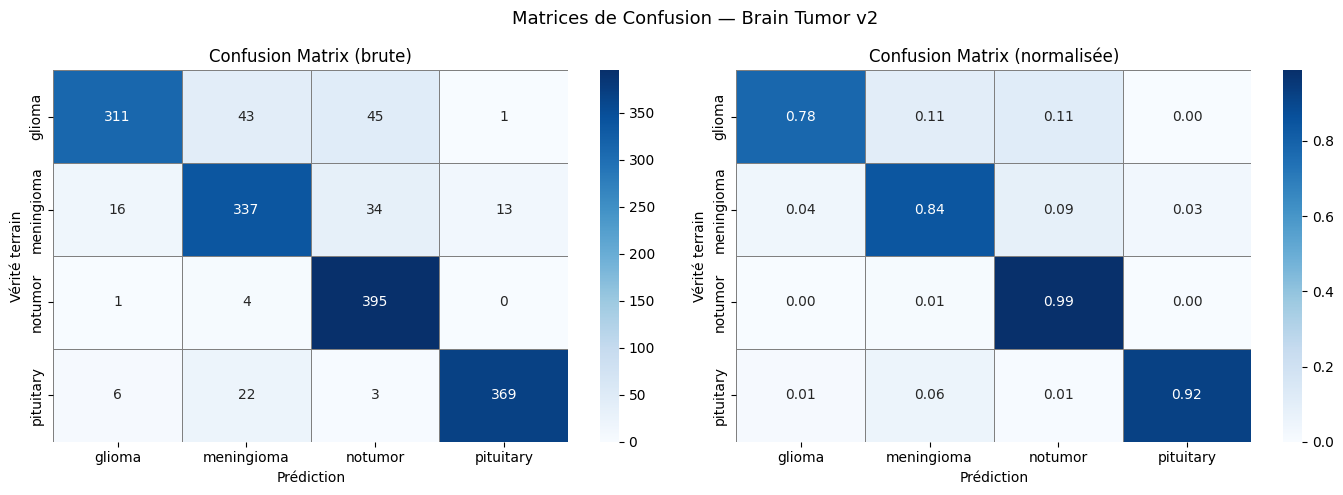


📈 ROC-AUC (macro-average) : 0.9692


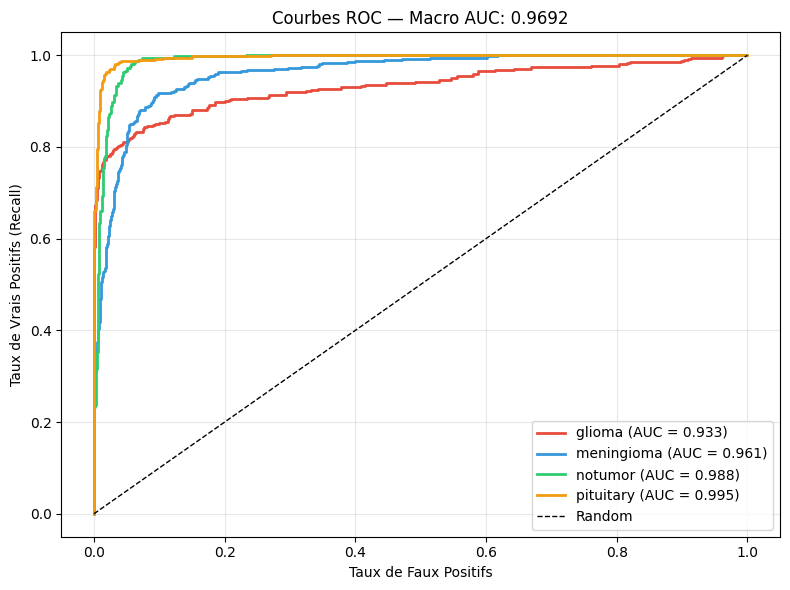


🎯 Recall par classe (métrique critique médicale):
   glioma       ███████████████░░░░░ 77.8% ⚠️  ATTENTION
   meningioma   ████████████████░░░░ 84.2% ⚠️  ATTENTION
   notumor      ███████████████████░ 98.8% ✅
   pituitary    ██████████████████░░ 92.2% ✅


In [33]:
# ============================================================
# 15. ÉVALUATION COMPLÈTE
# ============================================================

def evaluate_model(model, loader, class_names):

    model.eval()

    all_preds = []
    all_labels = []
    all_probs = []
    correct = total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs   = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)

            total   += labels.size(0)
            correct += (preds == labels).sum().item()

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    all_probs  = np.array(all_probs)
    all_labels = np.array(all_labels)
    all_preds  = np.array(all_preds)
    acc = 100.0 * correct / total

    print("\n" + "="*60)
    print(f"  TEST ACCURACY : {acc:.4f}%")
    print("="*60)
    print("\n📋 Classification Report:\n")
    print(classification_report(all_labels, all_preds, target_names=class_names))

    cm = confusion_matrix(all_labels, all_preds)
    print("\n🔢 Confusion Matrix (brute):\n", cm)

    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Matrices de Confusion — Brain Tumor v2", fontsize=13)

    for ax, data, title, fmt in zip(
        axes,
        [cm, cm_norm],
        ["Confusion Matrix (brute)", "Confusion Matrix (normalisée)"],
        ["d", ".2f"]
    ):
        sns.heatmap(data, annot=True, fmt=fmt,
                    xticklabels=class_names, yticklabels=class_names,
                    cmap="Blues", ax=ax, linewidths=0.5, linecolor="gray")
        ax.set_title(title)
        ax.set_xlabel("Prédiction")
        ax.set_ylabel("Vérité terrain")

    plt.tight_layout()
    plt.savefig("/content/confusion_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()

    # ROC-AUC
    y_bin = label_binarize(all_labels, classes=list(range(len(class_names))))
    roc_auc_macro = roc_auc_score(y_bin, all_probs, multi_class='ovr', average='macro')
    print(f"\n📈 ROC-AUC (macro-average) : {roc_auc_macro:.4f}")

    fig, ax = plt.subplots(figsize=(8, 6))
    colors = ["#e74c3c", "#3498db", "#2ecc71", "#f39c12"]

    for i, (name, color) in enumerate(zip(class_names, colors)):
        fpr, tpr, _ = roc_curve(y_bin[:, i], all_probs[:, i])
        roc_auc_i   = auc(fpr, tpr)
        ax.plot(fpr, tpr, color=color, lw=2,
                label=f"{name} (AUC = {roc_auc_i:.3f})")

    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random")
    ax.set_xlabel("Taux de Faux Positifs")
    ax.set_ylabel("Taux de Vrais Positifs (Recall)")
    ax.set_title(f"Courbes ROC — Macro AUC: {roc_auc_macro:.4f}")
    ax.legend(loc="lower right")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("/content/roc_curves.png", dpi=150, bbox_inches="tight")
    plt.show()

    print("\n🎯 Recall par classe (métrique critique médicale):")
    for i, name in enumerate(class_names):
        recall = cm[i, i] / cm[i].sum()
        bar    = "█" * int(recall * 20) + "░" * (20 - int(recall * 20))
        flag   = " ⚠️  ATTENTION" if recall < 0.85 else " ✅"
        print(f"   {name:<12} {bar} {recall*100:.1f}%{flag}")

    return acc, roc_auc_macro


acc, auc_score = evaluate_model(model, test_loader, class_names)


## 16. Fine-Tuning Phase 2 *(optionnel)*
> À activer **seulement si accuracy < 90%** après la phase 1.  
> Dégèle `features.4` en plus pour aller chercher des représentations plus profondes.


In [34]:
# ============================================================
# 16. FINE-TUNING PHASE 2 (OPTIONNEL)
#     — Si accuracy < 90%, dégeler encore plus de couches
# ============================================================

def fine_tune_phase2(model, epochs=10):
    """
    Phase 2 : Dégeler features.4, 5, 6, 7 + classifier
    Utiliser seulement si accuracy < 90% après phase 1
    """
    print("\n🔓 Phase 2 : Dégel profond des couches features.4+")

    UNFREEZE_PHASE2 = ["features.4", "features.5", "features.6", "features.7", "classifier"]

    for name, param in model.named_parameters():
        param.requires_grad = any(layer in name for layer in UNFREEZE_PHASE2)

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"   Paramètres entraînables : {trainable:,}")

    optimizer_p2 = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=2e-6, weight_decay=1e-4
    )
    scheduler_p2 = optim.lr_scheduler.CosineAnnealingLR(optimizer_p2, T_max=epochs, eta_min=1e-8)
    es_p2 = EarlyStopping(patience=5, path="/content/brain_tumor_phase2.pth")

    for epoch in range(epochs):
        model.train()
        running_loss = correct = total = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer_p2.zero_grad()
            outputs = model(images)
            loss    = criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer_p2.step()
            running_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

        scheduler_p2.step()
        print(f"  Phase2 Epoch [{epoch+1}/{epochs}] "
              f"Loss: {running_loss/len(train_loader):.4f} | Acc: {100*correct/total:.2f}%")

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                val_loss += criterion(model(images), labels).item()
        val_loss /= len(test_loader)

        es_p2(val_loss, model)
        if es_p2.stop:
            print(f"🛑 Early stopping phase 2 à l'epoch {epoch+1}")
            break

    model.load_state_dict(torch.load("/content/brain_tumor_phase2.pth"))
    return model


# ─── Décommenter pour activer ────────────────────────────────
# if acc < 90.0:
#     print(f"\n⚠️  Accuracy = {acc:.2f}% < 90% → Lancement Phase 2")
#     model = fine_tune_phase2(model, epochs=10)
#     acc, auc_score = evaluate_model(model, test_loader, class_names)


## 17. Sauvegarde Finale

In [35]:
# ============================================================
# 17. SAUVEGARDE FINALE
# ============================================================

final_path = "/content/brain_tumor_final_v2.pth"
torch.save({
    "model_state_dict":  model.state_dict(),
    "class_names":       class_names,
    "test_accuracy":     acc,
    "roc_auc":           auc_score,
    "architecture":      "efficientnet_b0",
    "unfreeze_layers":   ["features.5", "features.6", "features.7", "classifier"],
    "epochs_trained":    len(history["train_loss"]),
}, final_path)

print(f"\n✅ Modèle final sauvegardé → {final_path}")



✅ Modèle final sauvegardé → /content/brain_tumor_final_v2.pth


## 18. Résumé Final

In [36]:
# ============================================================
# 18. RÉSUMÉ FINAL
# ============================================================

print("\n" + "="*60)
print("  RÉSUMÉ FINAL")
print("="*60)
print(f"  Architecture   : EfficientNet-B0 (Fine-Tuning Profond)")
print(f"  Loss Function  : Focal Loss (γ=2.0) + Class Weights")
print(f"  Sampler        : WeightedRandomSampler (boost glioma x{GLIOMA_BOOST})")
print(f"  Optimizer      : AdamW + CosineAnnealing LR")
print(f"  Test Accuracy  : {acc:.2f}%")
print(f"  ROC-AUC (macro): {auc_score:.4f}")
print(f"  Epochs         : {len(history['train_loss'])}")
print("="*60)
print("\n  Fichiers générés :")
print("  📊 /content/training_curves.png")
print("  📊 /content/confusion_matrix.png")
print("  📊 /content/roc_curves.png")
print("  💾 /content/brain_tumor_best_v2.pth")
print("  💾 /content/brain_tumor_final_v2.pth")
print("="*60)



  RÉSUMÉ FINAL
  Architecture   : EfficientNet-B0 (Fine-Tuning Profond)
  Loss Function  : Focal Loss (γ=2.0) + Class Weights
  Sampler        : WeightedRandomSampler (boost glioma x1.5)
  Optimizer      : AdamW + CosineAnnealing LR
  Test Accuracy  : 88.25%
  ROC-AUC (macro): 0.9692
  Epochs         : 29

  Fichiers générés :
  📊 /content/training_curves.png
  📊 /content/confusion_matrix.png
  📊 /content/roc_curves.png
  💾 /content/brain_tumor_best_v2.pth
  💾 /content/brain_tumor_final_v2.pth
